# Train YOLO11s-seg (Ultralytics)

Thin runner over `iiss.models.yolo.train` (same code as `python -m iiss.train --run configs/runs/yolo_s<S>_seed42.yaml`). One notebook execution = one run; change only the parameters cell to launch another S.

- Run order (priority): the S=640 baseline first, then S=320 and S=960 (`.agent/experiments.md`).
- The 2-hour cap is cumulative per run id over all sessions, including hard kills (logged as `killed`). A capped or stopped run is continued with `RESUME = True`; a fresh start refuses to overwrite an existing `weights/last.pt`.
- The evaluated checkpoint is `weights/last.pt`; `best.pt` is logged only.
- Keep the outputs of this notebook after a real run: they are process evidence.
- `SMOKE = True`: 16 train / 8 valid images, S=320, 2 epochs, 5-minute cap, written to `runs/smoke/`.
- Keep the laptop plugged in and awake; close other GPU programs.

## Parameters

In [1]:
MODEL = 'yolo'
S = 320              # 320 / 640 / 960 -> configs/runs/yolo_s<S>_seed<SEED>.yaml
SEED = 42
RESUME = False       # True: continue from weights/last.pt (after a stop, crash or cap)
RUNS_ROOT = None     # None = runs/ in the repo (override, e.g. Google Drive on Colab)
SMOKE = False

## Config

In [2]:
import importlib

import pandas as pd
import torch
from IPython.display import display

from iiss.analysis.training import (config_table, gpu_sessions, notebook_config,
                                    plot_history, run_summary)
from iiss.models.common import run_dir
from iiss.utils.log import setup_logging

setup_logging()
cfg = notebook_config(MODEL, S, SEED, smoke=SMOKE, runs_root=RUNS_ROOT)
print(torch.__version__, torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
config_table(cfg)

2.14.1+cu126 NVIDIA GeForce RTX 4050 Laptop GPU


,value
run_id,yolo_s320_seed42
input_size,320
time_cap_hours,2.0
run_dir,C:\Users\Syauqi Nabil\Lectures\University\Seme...
train.epochs,100
train.batch,8
train.nbs,64
train.workers,4
train.patience,100
train.optimizer,auto


## Status before training

In [3]:
pd.Series(run_summary(cfg)).to_frame('value')

,value
run_id,yolo_s320_seed42
run_dir,C:\Users\Syauqi Nabil\Lectures\University\Seme...
last_pt,False
best_pt,False
epochs_done,0
epochs_planned,100
sessions,0
statuses,
gpu_hours_used,0.0
cap_hours,2.0


## Train

Logs stream below. Interrupting the kernel stops the run safely (state of the last finished epoch is kept).

In [4]:
module = importlib.import_module(f'iiss.models.{MODEL}')
out = module.train(cfg, resume=RESUME)
out

2026-11-24 00:39:49 INFO    iiss.utils.env: Wrote environment snapshot to C:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\runs\yolo_s320_seed42\env.json


2026-11-24 00:39:49 INFO    iiss.utils.seed: Seeded everything with seed=42 (deterministic=False)


2026-11-24 00:39:49 INFO    iiss.utils.timer: Timer started for yolo_s320_seed42: budget 7200 s, already used 0 s, remaining 7200 s


New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.215  Python-3.12.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\dataset\derived\yolo\data.yaml, degrees=0.0, deterministic=False, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance

... (3,921 outputs left out)

Speed: 0.2ms preprocess, 3.4ms inference, 0.0ms loss, 3.8ms postprocess per image


Results saved to C:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\runs\yolo_s320_seed42


2026-11-24 00:51:48 INFO    iiss.utils.timer: Timer stopped for yolo_s320_seed42: 718.5 s this session, status=completed, peak VRAM 1122.0 MB


WindowsPath('C:/Users/Syauqi Nabil/Lectures/University/Semester 5/Computer Vision/Task/Instance Segmentation/indoor-instance-seg-shift/runs/yolo_s320_seed42')

## Result

GPU time per session (`runs/gpu_time_log.csv`), run status and training curves (also saved as `<run_dir>/curves.png`). The validation curve of YOLO is Ultralytics' validator; the comparable numbers come from `predict_and_evaluate.ipynb`.

,run_id,start,end,wall_clock_s,gpu_name,peak_vram_mb,cap_hit,status
0,yolo_s320_seed42,2026-11-24T00:39:49+07:00,2026-11-24T00:51:48+07:00,718.5,NVIDIA GeForce RTX 4050 Laptop GPU,1122.0,False,completed


,value
run_id,yolo_s320_seed42
run_dir,C:\Users\Syauqi Nabil\Lectures\University\Seme...
last_pt,True
best_pt,True
epochs_done,100
epochs_planned,100
sessions,1
statuses,completed
gpu_hours_used,0.2
cap_hours,2.0


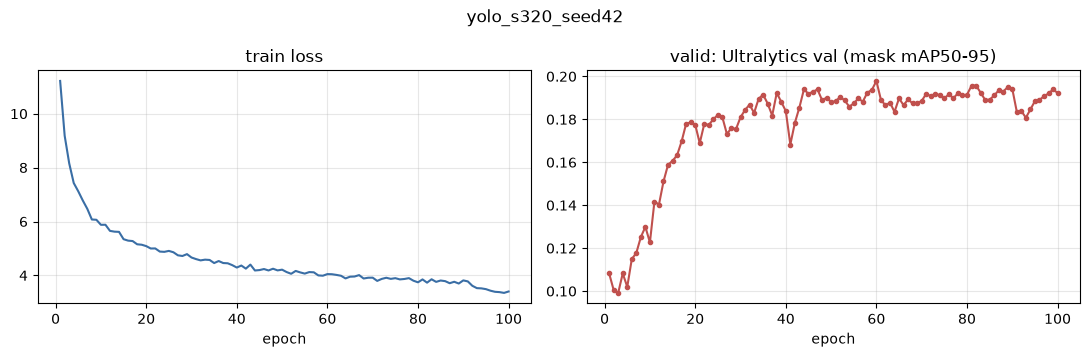

In [5]:
display(gpu_sessions(cfg))
display(pd.Series(run_summary(cfg)).to_frame('value'))
fig = plot_history(cfg, save_to=run_dir(cfg) / 'curves.png')

## Next step

Send back the summary table above (run id, epochs, GPU hours, last/best valid metric). Then run the next S, or `predict_and_evaluate.ipynb`.